# Prédire la qualité d'une soudure d'acier

Équipe n° __ : *Nom Prénom 1* (email), *Nom Prénom 2* (email), *Nom Prénom 3* (email)

Octobre 2026

Ce notebook sert de rapport. Chaque étape est expliquée avant le code, et les résultats sont commentés juste après.

## 1. Le problème et sa traduction en machine learning

La base ne donne pas de « note de qualité ». Elle donne des mesures mécaniques : limite d'élasticité, résistance, allongement et énergie de rupture Charpy. Nous avons donc défini la qualité comme le respect de critères normatifs, et séparé le problème en deux :

- **la traction** (la soudure est-elle assez résistante et assez déformable ?), traitée comme une classification conforme / non conforme ;
- **la ductilité** (la soudure casse-t-elle de façon fragile à froid ?), traitée par régression de l'énergie Charpy, puis comparée au seuil normatif. La section 4 explique pourquoi une classification directe ne fonctionnait pas ici.

Les deux propriétés ne sont presque jamais mesurées sur les mêmes soudures. Il faut donc deux modèles, combinés à la fin.

Les erreurs n'ont pas le même coût. Accepter une mauvaise soudure est bien plus grave que refuser une bonne soudure. Toute l'évaluation est donc tournée vers la détection des soudures non conformes.

## 2. Les données

La base *welddb* (Cooper, Bhadeshia et MacKay) décrit 1652 soudures avec 44 colonnes :

- 21 variables de composition chimique, en % massique ou en ppm ;
- les paramètres du procédé : courant, tension, type de courant, polarité, énergie de soudage, température entre passes, type de procédé et traitement thermique après soudage (PWHT) ;
- les propriétés mesurées, qui sont nos cibles potentielles.

Les valeurs manquantes sont notées `N`. Certaines valeurs sont des inégalités comme `<0.01`, d'autres des formats composites comme `67tot33res` pour l'azote.

In [1]:
import os
import re
import tarfile
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import (HistGradientBoostingClassifier, HistGradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, confusion_matrix,
                             mean_absolute_error, precision_score, r2_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import (GridSearchCV, GroupKFold, GroupShuffleSplit,
                                     StratifiedGroupKFold, StratifiedKFold)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.svm import SVC

RANDOM_STATE = 42

In [2]:
TAR_URL = "https://www.phase-trans.msm.cam.ac.uk/map/data/tar/welddb.tar"
DATA_DIR = os.path.join("..", "data")
TAR_PATH = os.path.join(DATA_DIR, "welddb.tar")
DATA_PATH = os.path.join(DATA_DIR, "welddb.data")

# Download and extract the data only once
os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(DATA_PATH):
    request = urllib.request.Request(TAR_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request) as response, open(TAR_PATH, "wb") as f:
        f.write(response.read())
    with tarfile.open(TAR_PATH) as tar:
        tar.extract("welddb.data", path=DATA_DIR)

# 'N' means missing value in the raw file
df_raw = pd.read_csv(DATA_PATH, sep=r"\s+", na_values=["N"], header=None)
print("Raw dataset shape:", df_raw.shape)

Raw dataset shape: (1652, 44)


In [3]:
COLUMN_NAMES = [
    # Chemical composition (21 columns)
    "C_wt", "Si_wt", "Mn_wt", "S_wt", "P_wt", "Ni_wt", "Cr_wt", "Mo_wt",
    "V_wt", "Cu_wt", "Co_wt", "W_wt", "O_ppm", "Ti_ppm", "N_ppm", "Al_ppm",
    "B_ppm", "Nb_ppm", "Sn_ppm", "As_ppm", "Sb_ppm",
    # Welding process
    "Current_A", "Voltage_V", "AC_DC", "Polarity", "Heat_input", "Interpass_temp", "Weld_type",
    # Post-weld heat treatment
    "PWHT_temp", "PWHT_time",
    # Measured properties
    "Yield_strength", "UTS", "Elongation", "Reduction_area", "Charpy_temp", "Charpy_energy",
    "Hardness", "FATT_50", "Primary_ferrite", "Ferrite_2nd_phase", "Acicular_ferrite",
    "Martensite", "Ferrite_carbide", "Weld_ID",
]
COMPOSITION_COLS = COLUMN_NAMES[:21]

df = df_raw.copy()
df.columns = COLUMN_NAMES
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1652 entries, 0 to 1651
Data columns (total 44 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   C_wt               1652 non-null   float64
 1   Si_wt              1652 non-null   float64
 2   Mn_wt              1652 non-null   float64
 3   S_wt               1648 non-null   str    
 4   P_wt               1642 non-null   float64
 5   Ni_wt              697 non-null    float64
 6   Cr_wt              784 non-null    float64
 7   Mo_wt              793 non-null    str    
 8   V_wt               928 non-null    str    
 9   Cu_wt              578 non-null    str    
 10  Co_wt              129 non-null    str    
 11  W_wt               75 non-null     str    
 12  O_ppm              1256 non-null   float64
 13  Ti_ppm             935 non-null    str    
 14  N_ppm              1242 non-null   str    
 15  Al_ppm             905 non-null    str    
 16  B_ppm              504 non-null    

### 2.1 Les valeurs manquantes

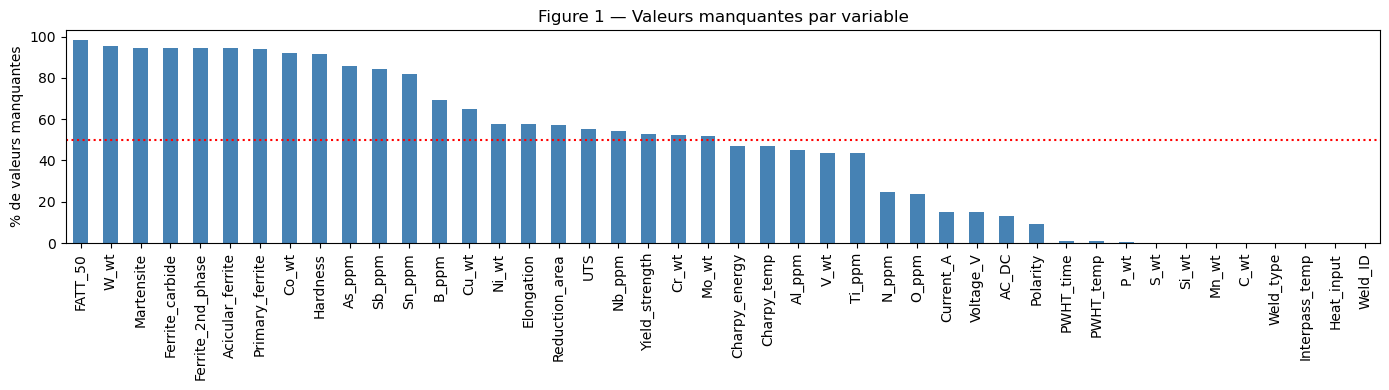

In [4]:
missing_pct = df.isna().mean().sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(14, 4))
missing_pct.plot.bar(ax=ax, color="steelblue")
ax.axhline(50, color="red", linestyle=":")
ax.set_ylabel("% de valeurs manquantes")
ax.set_title("Figure 1 — Valeurs manquantes par variable")
plt.tight_layout()
plt.show()

Trois choses ressortent :

- La composition de base (C, Si, Mn, S, P) est presque toujours renseignée.
- Les éléments d'alliage (Ni, Cr, Mo, V, Cu…) manquent très souvent. Ce n'est pas un oubli au hasard : en général, un élément qui n'est pas reporté n'a simplement pas été ajouté.
- Les cibles sont incomplètes. Moins de la moitié des soudures ont un essai de traction. La dureté et la FATT sont trop rares pour être utilisées.

### 2.2 Les procédés de soudage

In [5]:
# ShMA is the same process as MMA, and SA the same as SMA
df["Weld_type"] = df["Weld_type"].replace({"ShMA": "MMA", "SA": "SMA"})

has_tensile_test = df[["Yield_strength", "UTS", "Elongation"]].notna().all(axis=1)
has_charpy_test = df["Charpy_energy"].notna()

process_summary = pd.DataFrame({
    "soudures": df["Weld_type"].value_counts(),
    "avec essai de traction": has_tensile_test.groupby(df["Weld_type"]).sum(),
    "avec essai Charpy": has_charpy_test.groupby(df["Weld_type"]).sum(),
})
display(process_summary.sort_values("soudures", ascending=False))

,soudures,avec essai de traction,avec essai Charpy
Weld_type,,,
MMA,1180,489,673
SMA,261,127,61
FCA,87,7,63
TSA,87,24,63
NGSAW,18,4,14
NGGMA,7,2,5
GTAA,4,4,0
GMAA,4,4,0
SAA,4,4,0


Le soudage manuel à l'électrode enrobée (MMA) représente environ 70 % de la base et la grande majorité des essais. Les autres procédés ont une physique différente (protection gazeuse ou sous flux, autre dilution) et trop peu d'exemples pour être modélisés à part.

Nous avons donc concentré l'étude sur le MMA. Un modèle tous procédés confondus devrait apprendre en même temps les différences entre procédés, avec très peu d'exemples pour certains d'entre eux.

## 3. Le pré-traitement

Nos choix, avec leur justification :

- **Valeurs du type `<x`** : remplacées par x/2. La vraie valeur est quelque part entre 0 et la limite de détection, et x/2 est la convention habituelle en chimie analytique.
- **Formats composites** (`67tot33res`) : on garde le premier nombre, qui correspond à l'azote total.
- **Éléments d'alliage manquants** (Ni, Cr, Mo, V, Cu, Co, W, B, Nb, Sn, As, Sb) : remplacés par 0, puisqu'ils n'ont en général pas été ajoutés. Leur imputer la médiane reviendrait à inventer un alliage.
- **Oxygène, azote, titane et aluminium manquants** : imputés par la médiane, avec une colonne indiquant que la valeur manquait. Ces éléments sont toujours présents à l'état résiduel, donc 0 serait faux. L'indicateur permet au modèle d'apprendre si l'absence de mesure est elle-même informative.
- **Température entre passes notée `150-200`** : remplacée par 175 °C pour garder une variable numérique.
- **Dureté et FATT** : supprimées, car presque toujours absentes.
- **Variables catégorielles** (AC/DC, polarité) : encodées en one-hot.
- **Standardisation** : nécessaire pour la régression logistique, le SVM et l'ACP, sans effet sur les arbres.

L'imputation par la médiane et la standardisation sont faites **dans les pipelines scikit-learn**. Elles sont donc recalculées sur chaque jeu d'entraînement, et aucune information du test ne fuit vers l'apprentissage.

In [ ]:
def parse_measure(value):
    # Convert a raw composition entry (number, '<x' or '67tot33res') to a float
    if pd.isna(value):
        return np.nan
    text = str(value).strip()
    if text.startswith("<"):
        return float(text[1:]) / 2  # half the detection limit
    match = re.match(r"^-?\d*\.?\d+", text)
    if match:
        return float(match.group(0))
    return np.nan


df = df.drop(columns=["Hardness", "FATT_50"])
df = df[~df["Weld_type"].isin(["GMAA", "GTAA", "SAA", "NGGMA", "NGSAW"])].copy()

for col in COMPOSITION_COLS:
    df[col] = df[col].map(parse_measure)

ALLOY_ELEMENTS = ["Ni_wt", "Cr_wt", "Mo_wt", "V_wt", "Cu_wt", "Co_wt", "W_wt",
                  "B_ppm", "Nb_ppm", "Sn_ppm", "As_ppm", "Sb_ppm"]
df[ALLOY_ELEMENTS] = df[ALLOY_ELEMENTS].fillna(0)

df["Interpass_temp"] = df["Interpass_temp"].replace("150-200", "175")

numeric_cols = ["Interpass_temp", "Current_A", "Voltage_V", "Heat_input", "PWHT_temp", "PWHT_time",
                "Yield_strength", "UTS", "Elongation", "Charpy_temp", "Charpy_energy"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df_mma = df[df["Weld_type"] == "MMA"].copy()
print("soudures MMA conservées:", len(df_mma))

MMA welds kept: 1180


## 4. Les variables cibles : qu'est-ce qu'une bonne soudure ?

### 4.1 Les propriétés mesurées

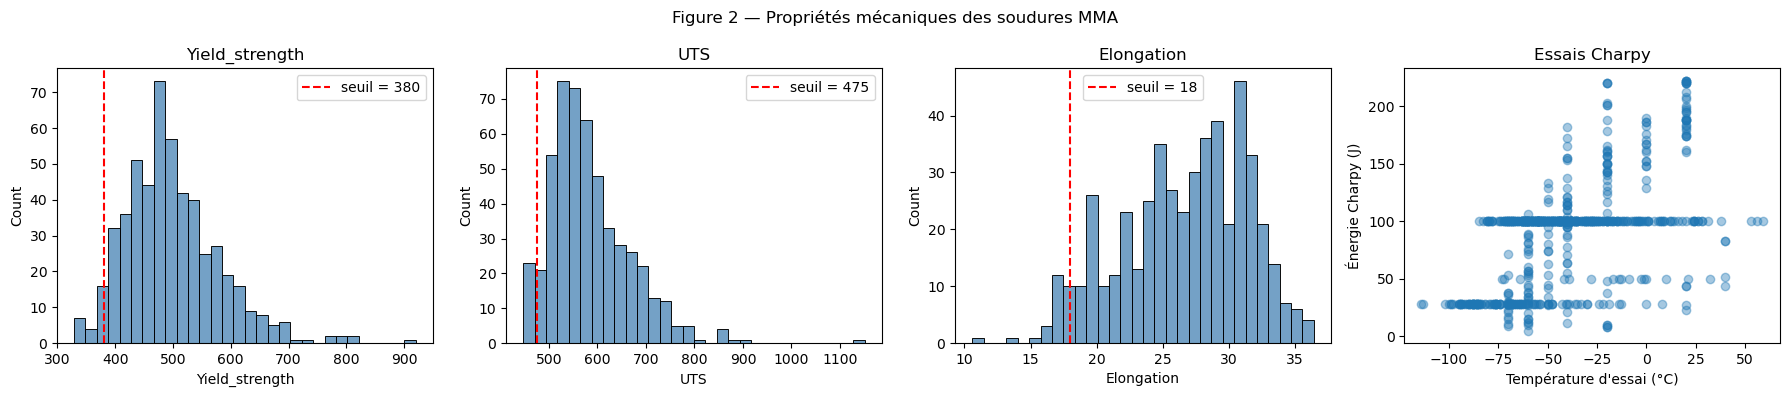

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

tensile_thresholds = {"Yield_strength": 380, "UTS": 475, "Elongation": 18}
for ax, (col, threshold) in zip(axes[:3], tensile_thresholds.items()):
    sns.histplot(df_mma[col].dropna(), bins=30, ax=ax, color="steelblue")
    ax.axvline(threshold, color="red", linestyle="--", label=f"seuil = {threshold}")
    ax.set_title(col)
    ax.legend()

axes[3].scatter(df_mma["Charpy_temp"], df_mma["Charpy_energy"], alpha=0.4)
axes[3].set_xlabel("Température d'essai (°C)")
axes[3].set_ylabel("Énergie Charpy (J)")
axes[3].set_title("Essais Charpy")

fig.suptitle("Figure 2 — Propriétés mécaniques des soudures MMA")
plt.tight_layout()
plt.show()

Le nuage Charpy montre la **courbe de transition ductile–fragile** : à froid, l'acier casse avec peu d'énergie, et à chaud il se déforme avant de rompre. La plupart des essais sont réalisés à basse température, souvent sous −20 °C.

### 4.2 Le critère de traction

Une soudure est jugée conforme en traction si :

- sa limite d'élasticité est d'au moins 380 MPa ;
- sa résistance à la traction est d'au moins 475 MPa ;
- son allongement est d'au moins 18 % ;
- le rapport limite d'élasticité / résistance ne dépasse pas 0,90.

Les trois premiers seuils sont proches de la classe 38 de la norme EN ISO 2560-A, qui exige en fait 20 % d'allongement : notre seuil est donc un peu plus tolérant. Nous n'avons pas mis de limite haute sur la résistance, car une soudure plus résistante que le métal de base est acceptée en construction. Le rapport Re/Rm garantit une réserve de plasticité : un métal dont la limite d'élasticité est trop proche de la rupture se déforme très peu avant de casser.

In [8]:
has_tensile = df_mma[["Yield_strength", "UTS", "Elongation"]].notna().all(axis=1)
tensile_ok = (
    (df_mma["Yield_strength"] >= 380)
    & (df_mma["UTS"] >= 475)
    & (df_mma["Elongation"] >= 18)
    & (df_mma["Yield_strength"] / df_mma["UTS"] <= 0.90)
)

# 1 = conforming, 0 = non-conforming, -1 = not tested
df_mma["Valid_Traction"] = -1
df_mma.loc[has_tensile & tensile_ok, "Valid_Traction"] = 1
df_mma.loc[has_tensile & ~tensile_ok, "Valid_Traction"] = 0
print(df_mma["Valid_Traction"].value_counts())

Valid_Traction
-1    691
 1    389
 0    100
Name: count, dtype: int64


Environ une soudure testée sur cinq est non conforme en traction. Le déséquilibre est modéré, et nous le compensons avec `class_weight="balanced"`.

### 4.3 Le critère de ductilité

Un essai Charpy donne un point (température, énergie) sur la courbe de transition de la soudure. La base contient deux sortes d'essais : soit on mesure l'énergie à une température donnée, soit on donne la température à laquelle on atteint 28, 50 ou 100 J. Dans les deux cas, c'est un point de la même courbe.

Un critère du type « au moins E_min joules à la température T_ref » porte sur **un autre point** de cette courbe. Comme l'énergie augmente avec la température, un essai ne permet de conclure que dans deux cas :

- l'énergie dépasse E_min à une température **inférieure ou égale** à T_ref : la soudure est conforme ;
- l'énergie reste sous E_min à une température **supérieure ou égale** à T_ref : la soudure est non conforme.

Dans tous les autres cas, l'essai ne permet pas de trancher.

Nous avons retenu **28 J à −20 °C**, pour trois raisons :

- c'est, à 1 J près, l'exigence de la nuance S355J2 (27 J à −20 °C, norme EN 10025-2), l'acier de construction le plus courant ;
- 28 J est le niveau de référence utilisé dans la base elle-même : beaucoup d'essais donnent directement la température à laquelle la soudure atteint 28 J. Ces essais se comparent donc exactement au critère ;
- le joule d'écart avec 27 J rend le critère très légèrement plus sévère, donc du côté de la sécurité.

Avant de construire un modèle, on vérifie combien d'essais permettent réellement de conclure, pour ce critère et pour quelques autres critères normatifs.

In [9]:
T = df_mma["Charpy_temp"]
E = df_mma["Charpy_energy"]

print("Most frequent test temperatures (°C):")
print(T.value_counts().head(8))

rows = []
for e_min in [28, 47]:
    for t_ref in [0, -20, -30, -40, -50, -60]:
        conforming = (E > e_min) & (T <= t_ref)
        non_conforming = (E <= e_min) & (T >= t_ref)
        rows.append({"E_min (J)": e_min, "T_ref (°C)": t_ref,
                     "conformes": int(conforming.sum()),
                     "non conformes": int(non_conforming.sum())})
display(pd.DataFrame(rows))

Most frequent test temperatures (°C):
Charpy_temp
-40.0    43
-20.0    42
-60.0    42
 20.0    37
-70.0    25
-50.0    24
 0.0     19
-55.0    14
Name: count, dtype: int64


,E_min (J),T_ref (°C),conformes,non conformes
0,28,0,459,4
1,28,-20,406,11
2,28,-30,341,15
3,28,-40,298,22
4,28,-50,198,31
5,28,-60,114,47
6,47,0,442,7
7,47,-20,389,15
8,47,-30,325,19
9,47,-40,282,26


Avec notre critère, environ 520 essais permettent de conclure, mais **une dizaine seulement sont non conformes**. Aucun critère, d'ailleurs, ne fait apparaître beaucoup de soudures fragiles : la base contient surtout des soudures conçues pour être tenaces, et la plupart des essais ont été faits à basse température pour le démontrer. Or un essai réussi à −60 °C prouve qu'une soudure est bonne à −20 °C, mais aucun essai fait sous −20 °C ne peut prouver qu'elle est mauvaise.

Un critère plus sévère, comme 47 J à −40 °C, donnerait davantage de soudures non conformes. Nous ne l'avons pas fait : choisir la définition de la qualité selon ce que le modèle arrive à séparer rendrait le raisonnement circulaire, et les scores ne prouveraient plus rien. Le critère doit venir de l'application, pas des données.

Nous gardons donc 28 J à −20 °C et nous changeons plutôt de méthode (section 10).

In [10]:
E_MIN = 28             # J, close to S355J2 (27 J) and the 28 J reference level of the database
CHARPY_REF_TEMP = -20  # °C

conforming = (E > E_MIN) & (T <= CHARPY_REF_TEMP)
non_conforming = (E <= E_MIN) & (T >= CHARPY_REF_TEMP)

df_mma["Valid_Ductile"] = -1
df_mma.loc[conforming, "Valid_Ductile"] = 1
df_mma.loc[non_conforming, "Valid_Ductile"] = 0

print(df_mma["Valid_Ductile"].value_counts())
print()
print(pd.crosstab(df_mma["Valid_Traction"], df_mma["Valid_Ductile"],
                  rownames=["Traction"], colnames=["Ductilité"]))

Valid_Ductile
-1    763
 1    406
 0     11
Name: count, dtype: int64

Ductilité   -1   0    1
Traction               
-1         374  11  306
 0          72   0   28
 1         317   0   72


Le tableau croisé confirme que peu de soudures ont les deux labels. On ne peut pas entraîner directement un modèle « bonne soudure » : il faut un modèle par propriété.

Avec une dizaine de soudures non conformes en ductilité, une classification directe ne peut ni apprendre ni être évaluée sérieusement : une seule erreur ferait varier le rappel d'environ 10 points. On modélisera donc **toute la courbe de transition** à partir de tous les essais Charpy (section 10), puis on comparera cette approche à une classification directe.

### 4.4 Les variables d'entrée

On ne garde que ce que le soudeur choisit **avant** de souder : la composition, les paramètres du procédé et le traitement thermique. Les propriétés mesurées après soudage, y compris la microstructure, sont exclues : les utiliser comme entrées reviendrait à donner la réponse au modèle. La température d'essai Charpy n'est utilisée que dans le modèle de ductilité, où c'est une condition d'essai.

In [11]:
NON_FEATURES = [
    "Weld_type", "Weld_ID", "Valid_Traction", "Valid_Ductile",
    "Charpy_temp", "Charpy_energy",
    "Yield_strength", "UTS", "Elongation", "Reduction_area",
    "Primary_ferrite", "Ferrite_2nd_phase", "Acicular_ferrite",
    "Martensite", "Ferrite_carbide",
]
X_all = df_mma.drop(columns=NON_FEATURES)

CAT_COLS = list(X_all.select_dtypes(exclude="number").columns)
NUM_COLS = list(X_all.select_dtypes(include="number").columns)
print(len(NUM_COLS), "numeric features")
print("Categorical features:", CAT_COLS)

# Only AC_DC and Polarity should be text; anything else means a parsing problem
assert set(CAT_COLS) <= {"AC_DC", "Polarity"}, CAT_COLS

27 numeric features
Categorical features: ['AC_DC', 'Polarity']


## 5. Le protocole d'évaluation

### 5.1 Les soudures jumelles

Plusieurs lignes de la base ont exactement la même composition. Il s'agit souvent du même métal déposé, testé brut de soudage puis après traitement thermique, ou à plusieurs températures. Avec un découpage aléatoire, une ligne pourrait être en entraînement et sa jumelle en test : le modèle reconnaîtrait la composition au lieu de généraliser.

Nous regroupons donc les soudures par composition, et chaque groupe reste entier d'un côté ou de l'autre du découpage.

In [12]:
chemistry_key = df_mma[COMPOSITION_COLS].round(4).fillna(-1).astype(str).agg("|".join, axis=1)
groups = pd.Series(pd.factorize(chemistry_key)[0], index=df_mma.index)

print("MMA welds:", len(df_mma))
print("Distinct compositions:", groups.nunique())
print(f"Welds per composition on average: {len(df_mma) / groups.nunique():.1f}")

MMA welds: 1180
Distinct compositions: 411
Welds per composition on average: 2.9


### 5.2 Le découpage

- On met de côté 20 % des compositions comme **jeu de test**. Elles sont tirées parmi les soudures qui ont un essai de traction ou un essai Charpy, et toutes les soudures partageant ces compositions vont dans le test, y compris celles sans essai. Le test ne sert qu'une fois, à la fin.
- Le reste forme le **jeu de développement**, qui contient aussi des soudures sans essai, utiles pour l'apprentissage semi-supervisé.
- Sur le développement, on compare les modèles et on règle les seuils par **validation croisée à 5 folds, groupée par composition**.

In [ ]:
has_charpy = df_mma[["Charpy_temp", "Charpy_energy"]].notna().all(axis=1)
tested = (df_mma["Valid_Traction"] != -1) | has_charpy
tested_index = df_mma.index[tested]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
_, test_positions = next(splitter.split(tested_index, groups=groups[tested_index]))
test_groups = set(groups[tested_index[test_positions]])

# Every weld sharing a test composition goes to the test set
is_test = groups.isin(test_groups)
df_dev = df_mma[~is_test]
df_test = df_mma[is_test]

X_dev = df_dev.drop(columns=NON_FEATURES)
X_test = df_test.drop(columns=NON_FEATURES)
groups_dev = groups[~is_test]

assert test_groups.isdisjoint(set(groups_dev)), "A composition is in both dev and test"
print("Development set:", len(df_dev), "soudures")
print("Test set:", len(df_test), "soudures")

Development set: 931 welds
Test set: 249 welds


In [14]:
def make_preprocessor(with_test_temperature=False):
    # Imputation + scaling for numbers, one-hot encoding for categories
    num_cols = NUM_COLS + ["Charpy_temp"] if with_test_temperature else NUM_COLS

    numeric_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ])
    categorical_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    preprocessor = ColumnTransformer([
        ("num", numeric_steps, num_cols),
        ("cat", categorical_steps, CAT_COLS),
    ])
    # Keep column names, needed later for the monotonic constraint
    return preprocessor.set_output(transform="pandas")

## 6. Une première intuition avec l'ACP

L'ACP sert ici à comprendre les données, pas à construire les modèles. Deux questions :

- les variables sont-elles redondantes ?
- les bonnes et les mauvaises soudures se séparent-elles facilement ?

On l'applique aux variables numériques standardisées. Sans standardisation, les variables en ppm écraseraient les autres.

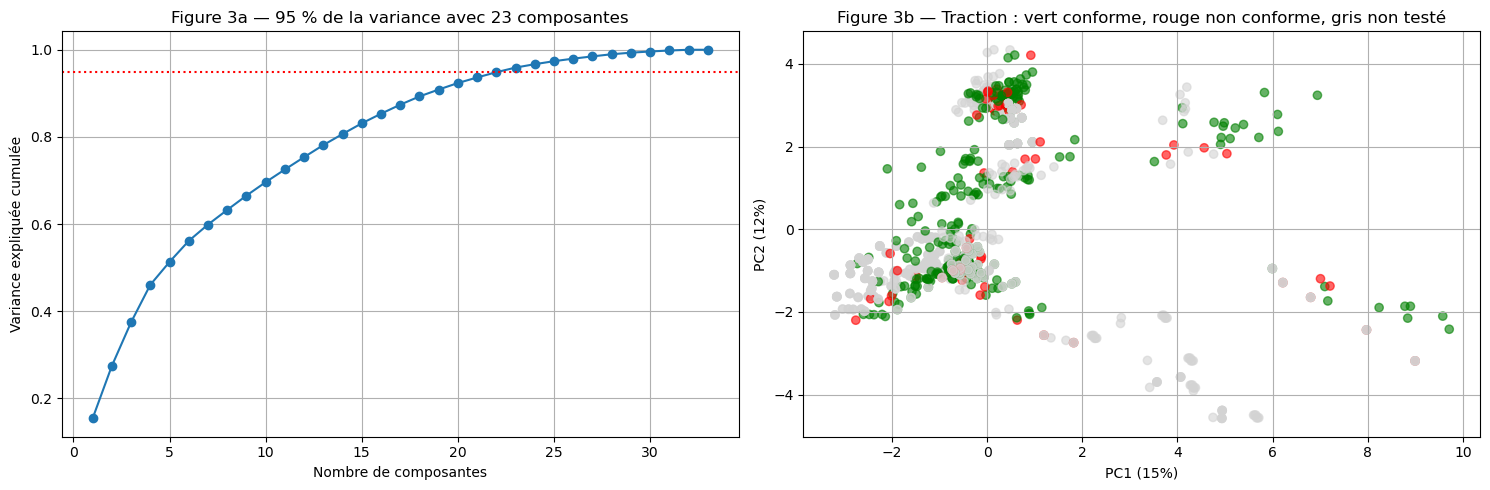

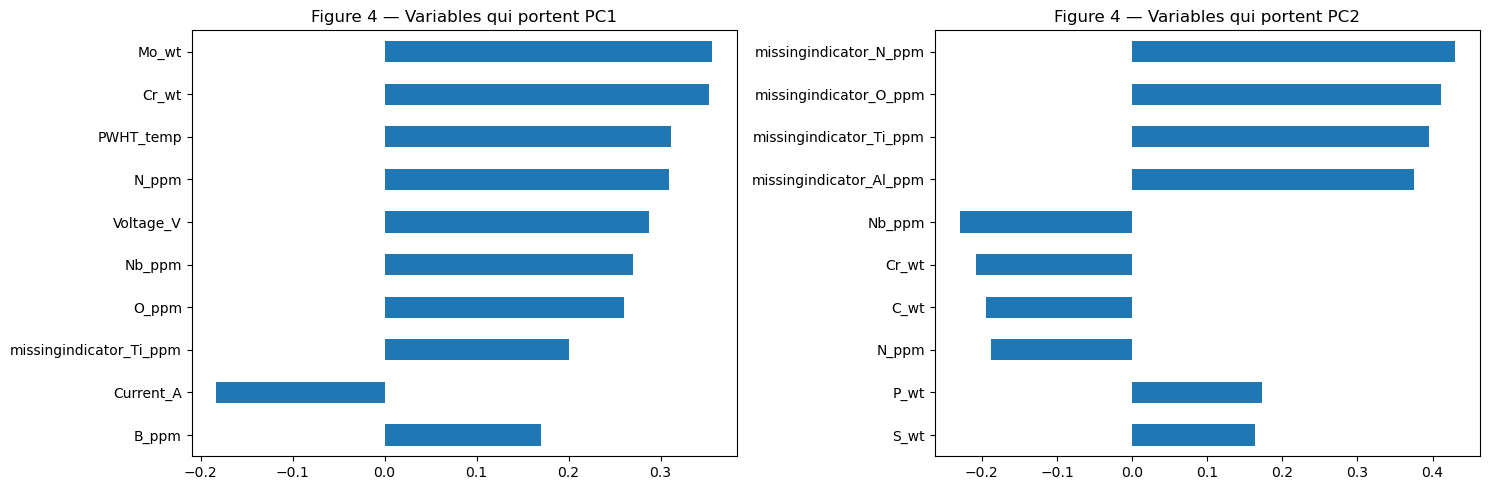

In [15]:
numeric_prep = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
]).set_output(transform="pandas")
X_dev_scaled = numeric_prep.fit_transform(X_dev[NUM_COLS])

pca = PCA().fit(X_dev_scaled)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
n_components_95 = int(np.argmax(cumulative_variance >= 0.95) + 1)
X_dev_pca = pca.transform(X_dev_scaled)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker="o")
axes[0].axhline(0.95, color="red", linestyle=":")
axes[0].set_xlabel("Nombre de composantes")
axes[0].set_ylabel("Variance expliquée cumulée")
axes[0].set_title(f"Figure 3a — 95 % de la variance avec {n_components_95} composantes")
axes[0].grid(True)

colors = df_dev["Valid_Traction"].map({1: "green", 0: "red", -1: "lightgray"})
axes[1].scatter(X_dev_pca[:, 0], X_dev_pca[:, 1], c=colors, alpha=0.6)
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
axes[1].set_title("Figure 3b — Traction : vert conforme, rouge non conforme, gris non testé")
axes[1].grid(True)
plt.tight_layout()
plt.show()

loadings = pd.DataFrame(pca.components_[:2].T, index=X_dev_scaled.columns, columns=["PC1", "PC2"])
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, component in zip(axes, ["PC1", "PC2"]):
    top = loadings[component].abs().sort_values(ascending=False).head(10).index
    loadings.loc[top, component].iloc[::-1].plot.barh(ax=ax)
    ax.set_title(f"Figure 4 — Variables qui portent {component}")
plt.tight_layout()
plt.show()

Il faut un grand nombre de composantes pour expliquer 95 % de la variance. Les variables sont donc peu redondantes, et réduire la dimension avant d'apprendre ferait perdre de l'information et le sens physique des variables. Nous n'utilisons pas l'ACP dans les modèles.

Les premiers axes opposent plutôt des familles d'aciers, par exemple les aciers alliés au chrome-molybdène et les aciers au carbone-manganèse, que des niveaux de qualité. Sur le plan PC1/PC2, les soudures conformes et non conformes se mélangent. La frontière entre les deux n'est pas linéaire, et on peut s'attendre à ce que les modèles à base d'arbres fassent mieux que la régression logistique.

## 7. Traction : méthodes

### 7.1 Les modèles comparés

- **Un modèle naïf**, qui prédit toujours la proportion moyenne. Il sert de point de comparaison.
- **La régression logistique**, simple et interprétable, qui teste si une frontière linéaire suffit.
- **Un SVM à noyau gaussien**, pour une frontière non linéaire et lisse.
- **Une forêt aléatoire**  : beaucoup d'arbres entraînés sur des sous-échantillons différents, dont on moyenne les votes. Elle gère bien les effets de seuil et les interactions, et elle supporte le bruit.
- **Le gradient boosting** : des arbres ajoutés un par un pour corriger les erreurs des précédents. 
### 7.2 L'apprentissage semi-supervisé

Plus de la moitié des soudures MMA n'ont pas d'essai de traction. Elles décrivent pourtant des compositions et des procédés réalistes. Nous avons testé le **self-training** :

1. on entraîne le modèle sur les soudures testées ;
2. il prédit les soudures non testées ;
3. on ajoute à l'apprentissage les prédictions dont il est sûr à plus de 80 % ;
4. on recommence jusqu'à ce qu'il n'y en ait plus de nouvelles.

Nous l'avons choisi parce qu'il fonctionne avec n'importe quel classifieur, ce qui permet de comparer supervisé et semi-supervisé à modèle égal. Les méthodes à base de graphe, comme le *label spreading*, supposent que deux soudures proches en distance ont la même qualité. C'est discutable avec des effets de seuil métallurgiques.

Le risque connu est que le modèle apprenne ses propres erreurs. Le seuil de 80 % le limite, et la comparaison sur les mêmes plis dira si le gain est réel.

### 7.3 Les métriques

La classe qui nous intéresse est celle des soudures non conformes (classe 0).

- **Rappel de la classe 0** : la part des mauvaises soudures que le modèle détecte. C'est notre métrique de sécurité.
- **Précision de la classe 1** : quand le modèle accepte une soudure, la probabilité qu'elle soit réellement bonne.
- **Exactitude équilibrée** : la moyenne des rappels des deux classes, qui ne se laisse pas tromper par le déséquilibre.
- **PR-AUC de la classe 0** : la qualité du classement des soudures à risque, indépendamment du seuil. Elle est plus parlante que la ROC-AUC quand la classe d'intérêt est rare. C'est notre **critère principal** pour comparer les modèles.
- **ROC-AUC** : la capacité générale à ordonner bonnes et mauvaises soudures. Une valeur de 0,5 correspond au hasard.
- **Taux d'acceptation** : la part des soudures acceptées. Un modèle qui refuse tout a un rappel parfait mais ne sert à rien.

In [16]:
SELF_TRAINING_THRESHOLD = 0.80


def compute_metrics(y_true, score, accepted):
    # score: higher means "more likely conforming"; accepted: final 0/1 decision
    y_true = np.asarray(y_true).astype(int)
    score = np.asarray(score, dtype=float)
    accepted = np.asarray(accepted).astype(int)
    both_classes = len(np.unique(y_true)) == 2
    return {
        "rec_0": recall_score(y_true, accepted, pos_label=0, zero_division=0),
        "prec_1": precision_score(y_true, accepted, pos_label=1, zero_division=0),
        "bal_acc": balanced_accuracy_score(y_true, accepted) if both_classes else np.nan,
        "pr_auc_0": average_precision_score(1 - y_true, -score) if both_classes else np.nan,
        "roc_auc": roc_auc_score(y_true, score) if both_classes else np.nan,
        "accept_rate": accepted.mean(),
    }


def make_classifier(clf, semi_supervised=False):
    if semi_supervised:
        clf = SelfTrainingClassifier(clone(clf), threshold=SELF_TRAINING_THRESHOLD)
    return Pipeline([("prep", make_preprocessor()), ("clf", clone(clf))])


def cross_val_probas(clf, X, y, groups, X_unlabeled=None, cv=None):
    # Out-of-fold probability of being conforming, for each labeled weld.
    # If X_unlabeled is given, it is added to every training fold (self-training).
    if cv is None:
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    semi_supervised = X_unlabeled is not None
    probas = pd.Series(np.nan, index=X.index)

    for train_idx, val_idx in cv.split(X, y, groups):
        X_train = X.iloc[train_idx]
        y_train = y.iloc[train_idx]
        if semi_supervised:
            X_train = pd.concat([X_train, X_unlabeled])
            y_train = pd.concat([y_train, pd.Series(-1, index=X_unlabeled.index)])

        model = make_classifier(clf, semi_supervised)
        model.fit(X_train, y_train)
        probas.iloc[val_idx] = model.predict_proba(X.iloc[val_idx])[:, 1]

    return probas


CLASSIFIERS = {
    "Modèle naïf": DummyClassifier(strategy="prior"),
    "Régression logistique": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "SVM": CalibratedClassifierCV(SVC(kernel="rbf", class_weight="balanced"), ensemble=False),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                              n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient boosting": HistGradientBoostingClassifier(class_weight="balanced",
                                                        random_state=RANDOM_STATE),
}

## 8. Traction : comparaison des modèles

### 8.1 Supervisé et semi-supervisé, en validation croisée groupée

In [17]:
is_labeled_tr = df_dev["Valid_Traction"] != -1
X_tr = X_dev[is_labeled_tr]
y_tr = df_dev.loc[is_labeled_tr, "Valid_Traction"]
groups_tr = groups_dev[is_labeled_tr]
X_tr_unlabeled = X_dev[~is_labeled_tr]

print(f"{len(y_tr)} labeled welds, {(y_tr == 0).sum()} non-conforming, "
      f"{len(X_tr_unlabeled)} unlabeled")

results = {}
for name, clf in CLASSIFIERS.items():
    p_supervised = cross_val_probas(clf, X_tr, y_tr, groups_tr)
    p_self_training = cross_val_probas(clf, X_tr, y_tr, groups_tr, X_unlabeled=X_tr_unlabeled)
    results[(name, "supervisé")] = compute_metrics(y_tr, p_supervised, p_supervised >= 0.5)
    results[(name, "self-training")] = compute_metrics(y_tr, p_self_training, p_self_training >= 0.5)

results_tr = pd.DataFrame(results).T.round(3)
display(results_tr)

380 labeled welds, 70 non-conforming, 551 unlabeled


rec_0  prec_1  bal_acc  pr_auc_0  \
Modèle naïf           supervisé      0.000   0.816    0.500     0.181   
                      self-training  0.000   0.816    0.500     0.181   
Régression logistique supervisé      0.514   0.858    0.588     0.321   
                      self-training  0.357   0.845    0.575     0.313   
SVM                   supervisé      0.000   0.816    0.500     0.134   
                      self-training  0.000   0.816    0.500     0.303   
Forêt aléatoire       supervisé      0.457   0.881    0.683     0.551   
                      self-training  0.371   0.867    0.650     0.507   
Gradient boosting     supervisé      0.443   0.876    0.665     0.434   
                      self-training  0.343   0.861    0.629     0.485   

                                     roc_auc  accept_rate  
Modèle naïf           supervisé        0.491        1.000  
                      self-training    0.491        1.000  
Régression logistique supervisé        0.650        0.629  
                      self-training    0.625        0.766  
SVM                   supervisé        0.315        1.000  
                      self-training    0.640        1.000  
Forêt aléatoire       supervisé        0.796        0.842  
                      self-training    0.773        0.874  
Gradient boosting     supervisé        0.742        0.826  
                      self-training    0.755        0.868

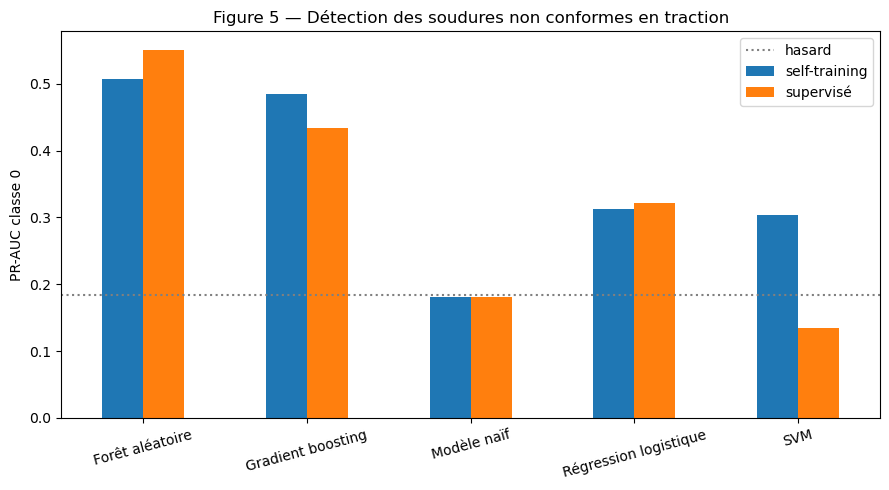

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))
results_tr["pr_auc_0"].unstack().plot.bar(ax=ax, rot=15)
ax.axhline((y_tr == 0).mean(), color="gray", linestyle=":", label="hasard")
ax.set_ylabel("PR-AUC classe 0")
ax.set_title("Figure 5 — Détection des soudures non conformes en traction")
ax.legend()
plt.tight_layout()
plt.show()

**Ce qu'on observe** (les valeurs citées viennent de notre exécution) :

- La **forêt aléatoire supervisée** obtient la meilleure PR-AUC (environ 0,54), la meilleure ROC-AUC (environ 0,79) et la meilleure exactitude équilibrée. Viennent ensuite le gradient boosting puis la régression logistique.
- Au seuil de 0,5, la régression logistique détecte un peu plus de mauvaises soudures, mais c'est un effet du seuil. Son classement des soudures, mesuré par la PR-AUC et la ROC-AUC, est nettement moins bon. C'est pour cela que l'on compare les modèles sans seuil, puis que l'on règle le seuil à part, en section 9.
- L'écart entre modèles linéaires et arbres confirme ce que suggérait l'ACP : la frontière est non linéaire.
- Le SVM est le moins bon modèle. Il est sensible au réglage de ses paramètres et ses probabilités sont peu fiables sur un petit jeu de données.
- **Le self-training n'améliore pas la forêt aléatoire.** Les pseudo-labels reproduisent les erreurs du modèle de départ, qui n'est pas assez bon pour s'auto-corriger. C'est un résultat négatif, mais il est utile : ajouter des données non labellisées n'aide pas automatiquement.

### 8.2 Que se passe-t-il si on ignore les soudures jumelles ?

On évalue la même forêt aléatoire avec un découpage aléatoire, sans regrouper par composition.

In [19]:
rf = CLASSIFIERS["Forêt aléatoire"]

p_grouped = cross_val_probas(rf, X_tr, y_tr, groups_tr)
random_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
p_random = cross_val_probas(rf, X_tr, y_tr, groups=None, cv=random_cv)

display(pd.DataFrame({
    "CV groupée": compute_metrics(y_tr, p_grouped, p_grouped >= 0.5),
    "CV aléatoire": compute_metrics(y_tr, p_random, p_random >= 0.5),
}).T.round(3))

,rec_0,prec_1,bal_acc,pr_auc_0,roc_auc,accept_rate
CV groupée,0.457,0.881,0.683,0.551,0.796,0.842
CV aléatoire,0.414,0.869,0.647,0.467,0.717,0.826


Si la validation croisée aléatoire donne de meilleurs scores

## 9. Traction : modèle final et seuil de sécurité

### 9.1 Réglage de la forêt aléatoire

On règle deux paramètres : la taille minimale des feuilles (`min_samples_leaf`), qui limite la complexité des arbres, et la part des variables tirées à chaque nœud (`max_features`), qui rend les arbres plus différents les uns des autres. La recherche utilise la même validation croisée groupée et maximise la PR-AUC de la classe 0.

Le réglage et l'évaluation utilisent les mêmes plis, ce qui rend les scores légèrement optimistes. Le jeu de test, lui, reste totalement indépendant.

In [20]:
def pr_auc_class0(model, X, y):
    probas = model.predict_proba(X)[:, 1]
    return average_precision_score(1 - np.asarray(y), -probas)


search = GridSearchCV(
    make_classifier(rf),
    param_grid={"clf__min_samples_leaf": [1, 3, 5, 10], "clf__max_features": ["sqrt", 0.5]},
    scoring=pr_auc_class0,
    cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1,
)
search.fit(X_tr, y_tr, groups=groups_tr)
print("Best parameters:", search.best_params_)
print(f"Best PR-AUC (class 0): {search.best_score_:.3f}")

rf_tuned = clone(rf).set_params(
    min_samples_leaf=search.best_params_["clf__min_samples_leaf"],
    max_features=search.best_params_["clf__max_features"],
)

Best parameters: {'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1}
Best PR-AUC (class 0): 0.587


### 9.2 Le seuil de sécurité

Par défaut, une soudure est acceptée si sa probabilité d'être conforme dépasse 0,5. Ce seuil ne correspond à aucun objectif industriel. On cherche plutôt **le plus petit seuil qui détecte au moins 90 % des soudures non conformes**, mesuré sur les prédictions de validation croisée.

Safety threshold for tensile model: 0.85


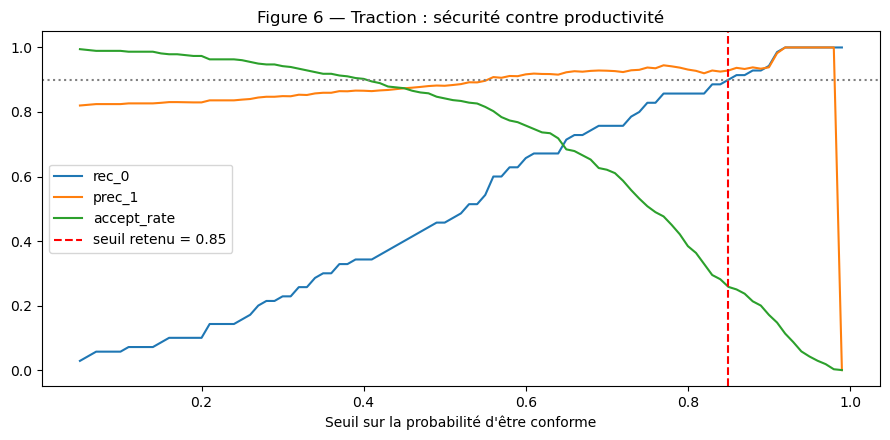

,rec_0,prec_1,bal_acc,pr_auc_0,roc_auc,accept_rate
validation croisée,0.9,0.929,0.597,0.551,0.796,0.258


In [21]:
TARGET_RECALL_0 = 0.90
THRESHOLDS = np.linspace(0.05, 0.99, 95)


def find_safe_threshold(y_true, probas, target=TARGET_RECALL_0):
    for threshold in THRESHOLDS:
        accepted = probas >= threshold
        if recall_score(y_true, accepted, pos_label=0) >= target:
            return float(threshold)
    raise ValueError(f"No threshold reaches a recall of {target} on non-conforming welds")


p_tr_oof = cross_val_probas(rf_tuned, X_tr, y_tr, groups_tr)
threshold_tr = find_safe_threshold(y_tr, p_tr_oof)
print(f"Safety threshold for tensile model: {threshold_tr:.2f}")

curve = pd.DataFrame(
    [compute_metrics(y_tr, p_tr_oof, p_tr_oof >= t) for t in THRESHOLDS], index=THRESHOLDS
)
fig, ax = plt.subplots(figsize=(9, 4.5))
curve[["rec_0", "prec_1", "accept_rate"]].plot(ax=ax)
ax.axvline(threshold_tr, color="red", linestyle="--", label=f"seuil retenu = {threshold_tr:.2f}")
ax.axhline(TARGET_RECALL_0, color="gray", linestyle=":")
ax.set_xlabel("Seuil sur la probabilité d'être conforme")
ax.set_title("Figure 6 — Traction : sécurité contre productivité")
ax.legend()
plt.tight_layout()
plt.show()

display(pd.Series(compute_metrics(y_tr, p_tr_oof, p_tr_oof >= threshold_tr)).round(3)
        .to_frame("validation croisée").T)

Le taux d'acceptation au seuil retenu montre le prix de la sécurité. Pour attraper 90 % des mauvaises soudures, le modèle doit aussi refuser une part importante de bonnes soudures, qui passeraient alors en essai destructif. Le modèle est un **outil de pré-tri**, pas un remplaçant des essais.

### 9.3 Évaluation sur le jeu de test

In [22]:
model_tr = make_classifier(rf_tuned).fit(X_tr, y_tr)

is_labeled_tr_test = df_test["Valid_Traction"] != -1
y_tr_test = df_test.loc[is_labeled_tr_test, "Valid_Traction"]
p_tr_test = model_tr.predict_proba(X_test[is_labeled_tr_test])[:, 1]

print(f"{len(y_tr_test)} test welds, {(y_tr_test == 0).sum()} non-conforming")
display(pd.Series(compute_metrics(y_tr_test, p_tr_test, p_tr_test >= threshold_tr)).round(3)
        .to_frame("test").T)
print("Confusion matrix (rows: true 0/1, columns: predicted 0/1)")
print(confusion_matrix(y_tr_test, (p_tr_test >= threshold_tr).astype(int), labels=[0, 1]))

109 test welds, 30 non-conforming


,rec_0,prec_1,bal_acc,pr_auc_0,roc_auc,accept_rate
test,0.967,0.97,0.686,0.676,0.831,0.303


Confusion matrix (rows: true 0/1, columns: predicted 0/1)
[[29  1]
 [47 32]]


Les scores de test sont à comparer à ceux de la validation croisée. Avec une vingtaine de soudures non conformes dans le test, le rappel peut varier d'une dizaine de points par simple hasard. Si on reste proche de 90 %, le seuil se généralise correctement.

## 10. Ductilité : modéliser la courbe de transition Charpy

### 10.1 Pourquoi une régression

Avec le critère 28 J à −20 °C, on ne dispose que d'une dizaine de soudures non conformes. Pourtant, des centaines d'autres essais Charpy sont des mesures valables : ils donnent simplement un autre point de la courbe de transition que celui du critère.

L'idée est d'apprendre directement **l'énergie Charpy en fonction de la composition, du procédé et de la température d'essai**, à partir de tous les essais. On lit ensuite sur la courbe prédite l'énergie à −20 °C, et on la compare à 28 J. C'est aussi l'approche suivie dans la littérature sur cette base.

Deux idées rendent cette approche solide :

- **La physique comme contrainte.** L'énergie Charpy augmente avec la température. On impose cette monotonie au modèle de gradient boosting. Une forêt aléatoire ne peut pas la garantir.
- **Une marge de sécurité calibrée.** Plutôt que l'énergie moyenne, on prédit une borne basse : la valeur sous laquelle l'énergie ne descend que dans 10 % des cas. On vérifie ensuite que cette borne est réellement respectée.

### 10.2 Les données Charpy

In [ ]:
def charpy_data(df_part, X_part):
    # Rows with a Charpy test, with the test temperature added as an input
    has_test = df_part[["Charpy_temp", "Charpy_energy"]].notna().all(axis=1)
    X_c = X_part[has_test].copy()
    X_c["Charpy_temp"] = df_part.loc[has_test, "Charpy_temp"]
    y_c = df_part.loc[has_test, "Charpy_energy"]
    return X_c, y_c, has_test


Xc_dev, yc_dev, has_charpy_dev = charpy_data(df_dev, X_dev)
Xc_test, yc_test, has_charpy_test = charpy_data(df_test, X_test)
groups_c_dev = groups_dev[has_charpy_dev]

n_conclusive = (df_dev["Valid_Ductile"] != -1).sum()
print(f"Charpy tests dans le set de développement: {len(yc_dev)} (seulement {n_conclusive} sont concluantes pour le critère)")
print(f"Charpy tests dans le set de test: {len(yc_test)}")


def at_reference_temperature(X_c):
    # Same welds, but as if they were tested at the reference temperature
    X_ref = X_c.copy()
    X_ref["Charpy_temp"] = CHARPY_REF_TEMP
    return X_ref

Charpy tests in development set: 517 (only 323 are conclusive for the criterion)
Charpy tests in test set: 156


### 10.3 Comparaison des modèles de régression

Quatre modèles, évalués en validation croisée groupée par composition :

- un modèle naïf, qui prédit toujours l'énergie médiane ;
- une régression Ridge (linéaire), qui devrait mal suivre une courbe en S ;
- une forêt aléatoire ;
- un gradient boosting contraint à être croissant en température.

On mesure l'erreur moyenne en joules (MAE), le R², et la capacité à repérer les essais fragiles, c'est-à-dire ceux où l'énergie mesurée ne dépasse pas 28 J.

In [24]:
MONOTONE_IN_TEMPERATURE = {"num__Charpy_temp": 1}

REGRESSORS = {
    "Modèle naïf": DummyRegressor(strategy="median"),
    "Ridge": RidgeCV(alphas=np.logspace(-2, 3, 20)),
    "Forêt aléatoire": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1,
                                             random_state=RANDOM_STATE),
    "Gradient boosting monotone": HistGradientBoostingRegressor(
        monotonic_cst=MONOTONE_IN_TEMPERATURE, random_state=RANDOM_STATE),
}


def make_regressor(reg):
    return Pipeline([("prep", make_preprocessor(with_test_temperature=True)), ("reg", clone(reg))])


def cross_val_energy(reg, X_c, y_c, groups_c):
    # Out-of-fold predicted energy, at the tested temperature and at the reference temperature
    pred_tested = pd.Series(np.nan, index=X_c.index)
    pred_ref = pd.Series(np.nan, index=X_c.index)

    for train_idx, val_idx in GroupKFold(n_splits=5).split(X_c, y_c, groups_c):
        model = make_regressor(reg)
        model.fit(X_c.iloc[train_idx], y_c.iloc[train_idx])
        X_val = X_c.iloc[val_idx]
        pred_tested.iloc[val_idx] = model.predict(X_val)
        pred_ref.iloc[val_idx] = model.predict(at_reference_temperature(X_val))

    return pred_tested, pred_ref


def regression_metrics(y_true, y_pred):
    brittle_true = y_true <= E_MIN
    brittle_pred = y_pred <= E_MIN
    found = (brittle_true & brittle_pred).sum()
    return {
        "MAE (J)": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "essais fragiles": int(brittle_true.sum()),
        "rappel fragiles": found / max(brittle_true.sum(), 1),
        "précision fragiles": found / max(brittle_pred.sum(), 1),
    }


oof_energy = {}
for name, reg in REGRESSORS.items():
    oof_energy[name] = cross_val_energy(reg, Xc_dev, yc_dev, groups_c_dev)

display(pd.DataFrame({name: regression_metrics(yc_dev, pred[0])
                      for name, pred in oof_energy.items()}).T.round(3))

,MAE (J),R2,essais fragiles,rappel fragiles,précision fragiles
Modèle naïf,29.905,-0.063,113.0,0.000,0.000
Ridge,24.198,0.559,113.0,0.159,0.783
Forêt aléatoire,15.314,0.758,113.0,0.018,1.000
Gradient boosting monotone,17.208,0.752,113.0,0.265,0.968


Le nombre d'essais fragiles utilisés est bien plus grand que la dizaine de soudures non conformes du critère : le modèle apprend enfin où se situe la transition. L'écart entre le Ridge et les modèles d'arbres montre à quel point la courbe est non linéaire.

### 10.4 Les courbes prédites sont-elles physiquement crédibles ?

On trace la courbe prédite pour quelques compositions testées à plusieurs températures, avec leurs essais réels. On compte aussi la part des soudures dont la courbe prédite **descend** quand la température monte, ce qui est physiquement impossible.

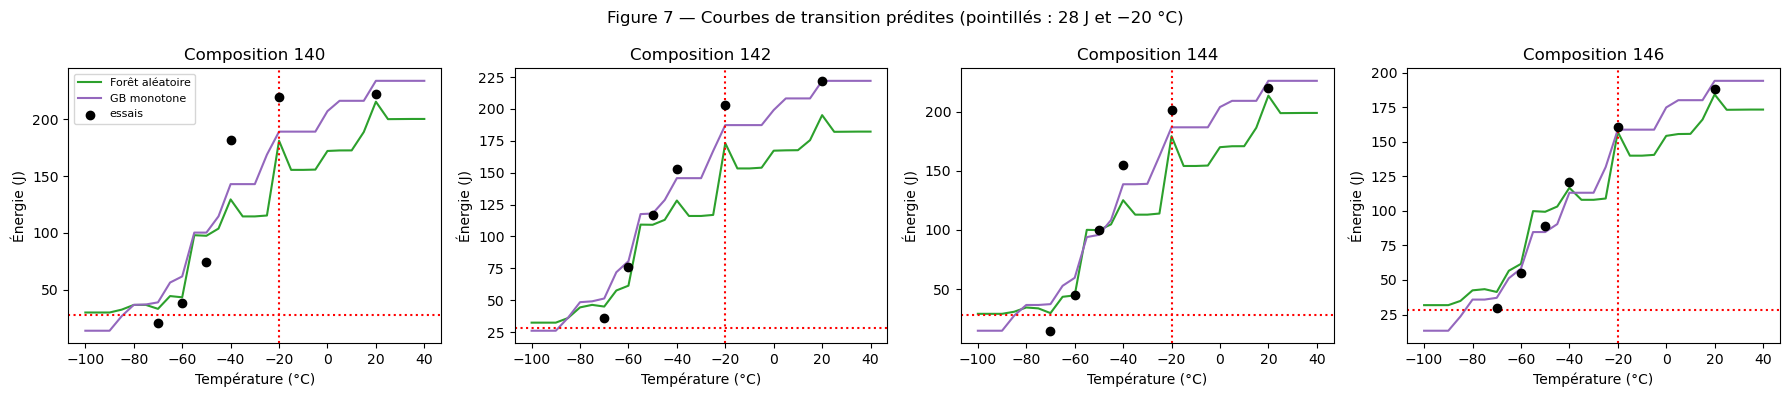

Random forest: 100% of curves decrease somewhere
Monotone gradient boosting: 0%


In [25]:
rf_energy = make_regressor(REGRESSORS["Forêt aléatoire"]).fit(Xc_dev, yc_dev)
gb_energy = make_regressor(REGRESSORS["Gradient boosting monotone"]).fit(Xc_dev, yc_dev)

temperatures = np.arange(-100, 41, 5)
tests_per_composition = groups_c_dev.value_counts()
example_compositions = tests_per_composition.index[:4]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, composition in zip(axes, example_compositions):
    rows = groups_c_dev.index[groups_c_dev == composition]
    one_weld = Xc_dev.loc[[rows[0]]]
    curve_input = pd.concat([one_weld] * len(temperatures))
    curve_input["Charpy_temp"] = temperatures

    ax.plot(temperatures, rf_energy.predict(curve_input), label="Forêt aléatoire", color="tab:green")
    ax.plot(temperatures, gb_energy.predict(curve_input), label="GB monotone", color="tab:purple")
    ax.scatter(Xc_dev.loc[rows, "Charpy_temp"], yc_dev.loc[rows], color="black", zorder=3,
               label="essais")
    ax.axhline(E_MIN, color="red", linestyle=":")
    ax.axvline(CHARPY_REF_TEMP, color="red", linestyle=":")
    ax.set_xlabel("Température (°C)")
    ax.set_ylabel("Énergie (J)")
    ax.set_title(f"Composition {composition}")
axes[0].legend(fontsize=8)
fig.suptitle("Figure 7 — Courbes de transition prédites (pointillés : 28 J et −20 °C)")
plt.tight_layout()
plt.show()


def share_of_decreasing_curves(model, X_c):
    welds = X_c.drop_duplicates(subset=NUM_COLS).head(200)
    predictions = []
    for t in temperatures:
        X_t = welds.copy()
        X_t["Charpy_temp"] = t
        predictions.append(model.predict(X_t))
    predictions = np.column_stack(predictions)
    # A drop of more than 1 J between two consecutive temperatures is non-physical
    decreasing = (np.diff(predictions, axis=1) < -1).any(axis=1)
    return decreasing.mean()


print(f"Random forest: {share_of_decreasing_curves(rf_energy, Xc_dev):.0%} of curves decrease somewhere")
print(f"Monotone gradient boosting: {share_of_decreasing_curves(gb_energy, Xc_dev):.0%}")

La forêt aléatoire produit des courbes en escalier qui peuvent redescendre quand la température monte, ce qui ne correspond à aucune réalité physique pour un acier ferritique. Le gradient boosting monotone l'interdit par construction. C'est le modèle que nous retenons pour la ductilité, même si son erreur moyenne est proche de celle de la forêt : une prédiction physiquement impossible n'est pas acceptable pour un outil de décision.

### 10.5 Une borne basse calibrée

On entraîne un second gradient boosting monotone qui prédit le **quantile 10 %** de l'énergie. En principe, seuls 10 % des essais réels devraient tomber sous cette borne.

En pratique, sur des compositions jamais vues, le quantile appris est souvent trop optimiste. On le corrige par **régression quantile conformalisée** : on mesure en validation croisée de combien il faut abaisser la borne pour que 10 % seulement des essais tombent en dessous, puis on applique ce décalage partout. La vérification finale se fait sur le jeu de test.

**Règle de décision :** une soudure est jugée ductile si sa borne basse à −20 °C dépasse 28 J.

In [26]:
QUANTILE = 0.10
gb_lower = HistGradientBoostingRegressor(loss="quantile", quantile=QUANTILE,
                                         monotonic_cst=MONOTONE_IN_TEMPERATURE,
                                         random_state=RANDOM_STATE)

lower_tested, lower_ref = cross_val_energy(gb_lower, Xc_dev, yc_dev, groups_c_dev)
print(f"Before calibration: {(yc_dev < lower_tested).mean():.1%} of tests below the lower bound "
      f"(target {QUANTILE:.0%})")

# Shift so that exactly 10% of the cross-validated tests fall below the bound
CQR_SHIFT = float(np.quantile(lower_tested - yc_dev, 1 - QUANTILE))
lower_tested = lower_tested - CQR_SHIFT
lower_ref = lower_ref - CQR_SHIFT
print(f"Calibration shift: {CQR_SHIFT:+.1f} J")
print(f"After calibration: {(yc_dev < lower_tested).mean():.1%} of tests below the lower bound")

Before calibration: 20.7% of tests below the lower bound (target 10%)
Calibration shift: +5.2 J
After calibration: 10.1% of tests below the lower bound


### 10.6 Régression ou classification directe ?

Pour justifier ce choix, on compare quand même avec une classification directe sur les essais concluants, sur les mêmes soudures et en validation croisée :

- une forêt aléatoire de classification entraînée sur les seuls essais concluants, au seuil de 0,5 puis au seuil de sécurité (90 % des non-conformes détectés) ;
- la décision tirée de la régression, à partir de l'énergie médiane prédite à −20 °C ;
- la décision tirée de la régression, à partir de la borne basse calibrée.

In [27]:
# Conclusive welds of the development set
is_conclusive = df_dev["Valid_Ductile"] != -1
X_du = X_dev[is_conclusive]
y_du = df_dev.loc[is_conclusive, "Valid_Ductile"]
groups_du = groups_dev[is_conclusive]
print(f"{len(y_du)} conclusive welds, {(y_du == 0).sum()} non-conforming")

# Direct classification
p_du_oof = cross_val_probas(rf, X_du, y_du, groups_du)
threshold_du = find_safe_threshold(y_du, p_du_oof)

# Regression-based decisions, read on the same welds
median_ref = oof_energy["Gradient boosting monotone"][1][y_du.index]
lower_ref_du = lower_ref[y_du.index]

comparison = {
    "Classification, seuil 0,5": compute_metrics(y_du, p_du_oof, p_du_oof >= 0.5),
    f"Classification, seuil de sécurité ({threshold_du:.2f})":
        compute_metrics(y_du, p_du_oof, p_du_oof >= threshold_du),
    f"Régression, énergie médiane > {E_MIN} J": compute_metrics(y_du, median_ref, median_ref > E_MIN),
    f"Régression, borne basse > {E_MIN} J": compute_metrics(y_du, lower_ref_du, lower_ref_du > E_MIN),
}
display(pd.DataFrame(comparison).T.round(3))

323 conclusive welds, 10 non-conforming


,rec_0,prec_1,bal_acc,pr_auc_0,roc_auc,accept_rate
"Classification, seuil 0,5",1.0,1.000,1.000,1.0,1.0,0.969
"Classification, seuil de sécurité (0.15)",1.0,1.000,1.000,1.0,1.0,0.969
"Régression, énergie médiane > 28 J",0.6,0.987,0.800,1.0,1.0,0.981
"Régression, borne basse > 28 J",1.0,1.000,0.997,1.0,1.0,0.963


Pour lire ce tableau, il faut regarder ensemble le rappel de la classe 0 et le taux d'acceptation : à rappel égal, le meilleur modèle est celui qui accepte le plus de soudures. Avec une dizaine de non-conformes seulement, ces chiffres restent fragiles : une soudure détectée de plus ou de moins change le rappel d'environ 10 points. Il ne faut donc pas sur-interpréter de petits écarts.

La régression a deux avantages qui ne se lisent pas dans ces chiffres :

- elle a appris sur tous les essais Charpy, pas seulement sur la dizaine de cas non conformes ;
- elle reste valable si l'on change de critère (section 10.8), alors qu'une classification devrait être réentraînée et perdrait encore des exemples.

### 10.7 Modèles finaux et jeu de test

Accuracy of the predicted curve on the test set:


,MAE (J),R2,essais fragiles,rappel fragiles,précision fragiles
test,16.129,0.787,28.0,0.286,0.889


Tests below the calibrated lower bound: 1.9% (target 10%)

Decision on 94 conclusive test welds (1 non-conforming):


,rec_0,prec_1,bal_acc,pr_auc_0,roc_auc,accept_rate
test,1.0,1.0,0.731,0.02,0.677,0.457


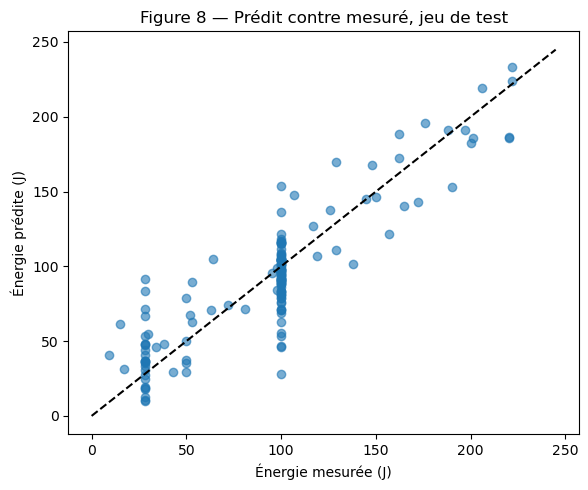

In [28]:
energy_model = make_regressor(REGRESSORS["Gradient boosting monotone"]).fit(Xc_dev, yc_dev)
lower_model = make_regressor(gb_lower).fit(Xc_dev, yc_dev)


def lower_bound_at_reference(X):
    # Calibrated lower bound of the Charpy energy at the reference temperature
    X_ref = X.copy()
    X_ref["Charpy_temp"] = CHARPY_REF_TEMP
    return lower_model.predict(X_ref) - CQR_SHIFT


energy_test = energy_model.predict(Xc_test)
lower_test = lower_model.predict(Xc_test) - CQR_SHIFT

print("Accuracy of the predicted curve on the test set:")
display(pd.Series(regression_metrics(yc_test, energy_test)).round(3).to_frame("test").T)
print(f"Tests below the calibrated lower bound: {(yc_test.values < lower_test).mean():.1%} "
      f"(target {QUANTILE:.0%})")

is_conclusive_test = df_test["Valid_Ductile"] != -1
y_du_test = df_test.loc[is_conclusive_test, "Valid_Ductile"]
lower_du_test = lower_bound_at_reference(X_test[is_conclusive_test])
print(f"\nDecision on {len(y_du_test)} conclusive test welds ({(y_du_test == 0).sum()} non-conforming):")
display(pd.Series(compute_metrics(y_du_test, lower_du_test, lower_du_test > E_MIN)).round(3)
        .to_frame("test").T)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(yc_test, energy_test, alpha=0.6)
max_energy = max(yc_test.max(), energy_test.max()) * 1.05
ax.plot([0, max_energy], [0, max_energy], "k--")
ax.set_xlabel("Énergie mesurée (J)")
ax.set_ylabel("Énergie prédite (J)")
ax.set_title("Figure 8 — Prédit contre mesuré, jeu de test")
plt.tight_layout()
plt.show()

La courbe est maintenant évaluée sur **tous les essais du test**, et non plus sur une poignée de soudures non conformes. Si la part des essais sous la borne basse reste proche de 10 %, la marge de sécurité tient sur des compositions jamais vues.

La décision finale à −20 °C, en revanche, ne peut être vérifiée que sur les quelques soudures concluantes du test. C'est la limite qui reste, et elle vient de la base elle-même.

### 10.8 Sensibilité au choix du critère

Comme la courbe complète est apprise, on peut appliquer d'autres critères sans réentraîner. On calcule, pour toutes les soudures MMA, la part jugée ductile selon plusieurs critères normatifs.

In [29]:
X_mma = df_mma.drop(columns=NON_FEATURES)
criteria = {
    "28 J à −20 °C (critère retenu)": (28, -20),
    "28 J à −40 °C": (28, -40),
    "47 J à −20 °C (EN ISO 2560-A, symbole 2)": (47, -20),
    "47 J à −40 °C (EN ISO 2560-A, symbole 4)": (47, -40),
}

sensitivity = {}
for name, (e_min, t_ref) in criteria.items():
    X_t = X_mma.copy()
    X_t["Charpy_temp"] = t_ref
    lower = lower_model.predict(X_t) - CQR_SHIFT
    sensitivity[name] = {"part jugée ductile": np.mean(lower > e_min)}
display(pd.DataFrame(sensitivity).T.round(3))

,part jugée ductile
28 J à −20 °C (critère retenu),0.408
28 J à −40 °C,0.397
"47 J à −20 °C (EN ISO 2560-A, symbole 2)",0.276
"47 J à −40 °C (EN ISO 2560-A, symbole 4)",0.251


Plus le critère est sévère, plus la part de soudures jugées ductiles diminue. Cela montre que le choix de la norme pèse autant que le modèle : avant d'utiliser un tel outil, il faut fixer la température de service de la structure.

## 11. Ce que les modèles ont appris, et nos recommandations

### 11.1 Les variables qui comptent

On mesure l'importance d'une variable en la mélangeant aléatoirement et en regardant de combien la performance se dégrade sur le jeu de test (importance par permutation). C'est plus fiable que l'importance interne des forêts, qui favorise les variables continues à beaucoup de valeurs.

Pour la ductilité, la température d'essai arrive logiquement en tête, puisque c'est la physique de la transition. Les variables qui suivent sont celles qui intéressent le concepteur.

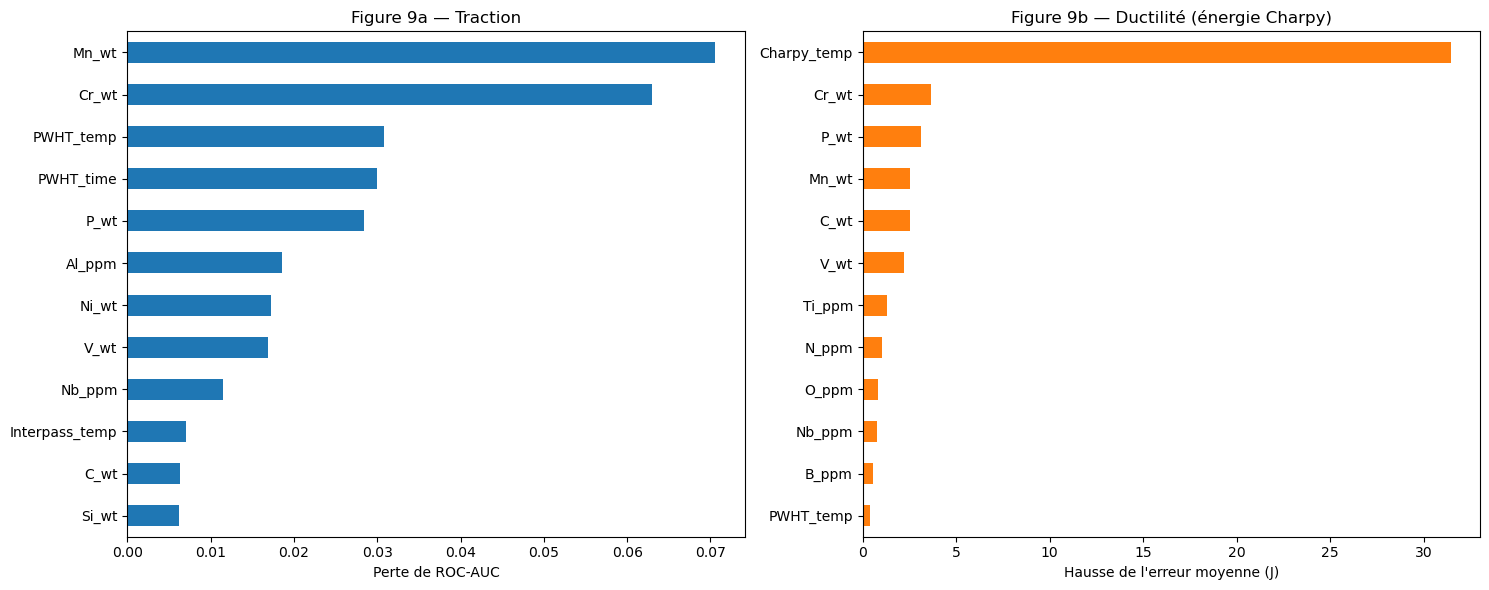

In [30]:
imp_tr = permutation_importance(model_tr, X_test[is_labeled_tr_test], y_tr_test, scoring="roc_auc",
                                n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
importance_tr = pd.Series(imp_tr.importances_mean, index=X_test.columns).sort_values(ascending=False)

imp_du = permutation_importance(energy_model, Xc_test, yc_test, scoring="neg_mean_absolute_error",
                                n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
importance_du = pd.Series(imp_du.importances_mean, index=Xc_test.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
importance_tr.head(12).iloc[::-1].plot.barh(ax=axes[0], color="tab:blue")
axes[0].set_title("Figure 9a — Traction")
axes[0].set_xlabel("Perte de ROC-AUC")
importance_du.head(12).iloc[::-1].plot.barh(ax=axes[1], color="tab:orange")
axes[1].set_title("Figure 9b — Ductilité (énergie Charpy)")
axes[1].set_xlabel("Hausse de l'erreur moyenne (J)")
plt.tight_layout()
plt.show()

### 11.2 Dans quel sens agissent ces variables ?

L'importance dit quelles variables comptent, pas dans quel sens. Pour chacune des plus importantes, on fait varier sa valeur pour toutes les soudures, en gardant les autres variables telles quelles, et on suit la prédiction moyenne (dépendance partielle). Pour la ductilité, la prédiction est l'énergie à −20 °C.

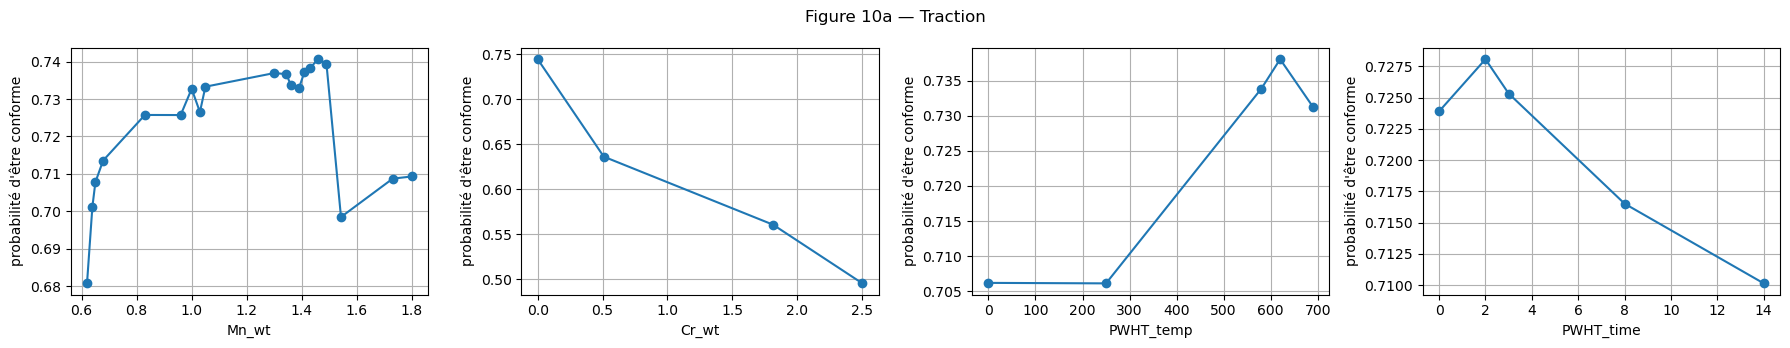

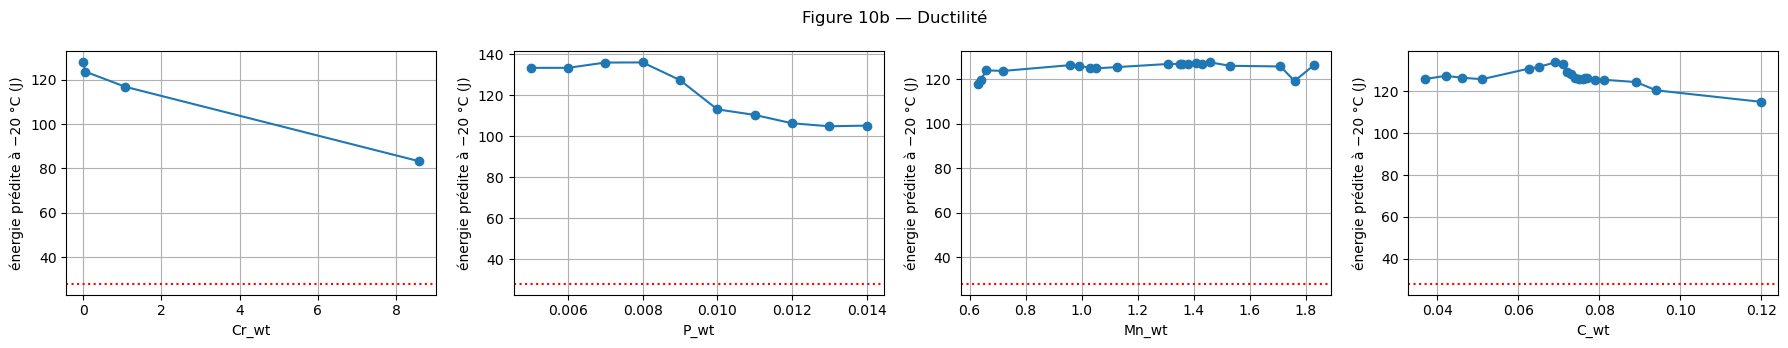

In [31]:
def partial_dependence(model, X, feature, n_points=20):
    grid = np.unique(np.quantile(X[feature].dropna(), np.linspace(0.05, 0.95, n_points)))
    averages = []
    for value in grid:
        X_modified = X.copy()
        X_modified[feature] = value
        if hasattr(model, "predict_proba"):
            averages.append(model.predict_proba(X_modified)[:, 1].mean())
        else:
            averages.append(model.predict(X_modified).mean())
    return grid, averages


def plot_partial_dependence(model, X, features, ylabel, title, threshold=None):
    fig, axes = plt.subplots(1, len(features), figsize=(4.5 * len(features), 3.5))
    for ax, feature in zip(axes, features):
        grid, averages = partial_dependence(model, X, feature)
        ax.plot(grid, averages, marker="o")
        if threshold is not None:
            ax.axhline(threshold, color="red", linestyle=":")
        ax.set_xlabel(feature)
        ax.set_ylabel(ylabel)
        ax.grid(True)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


top_tr = [f for f in importance_tr.index if f in NUM_COLS][:4]
plot_partial_dependence(model_tr, X_tr, top_tr, "probabilité d'être conforme",
                        "Figure 10a — Traction")

top_du = [f for f in importance_du.index if f in NUM_COLS][:4]
plot_partial_dependence(energy_model, at_reference_temperature(Xc_dev), top_du,
                        "énergie prédite à −20 °C (J)", "Figure 10b — Ductilité", threshold=E_MIN)

### 11.3 Points d'attention pour une bonne soudure MMA

**Ce que l'on peut conclure, et ce que l'on ne peut pas**

Nos modèles apprennent des corrélations dans une base de soudures publiées, pas des relations de cause à effet. L'importance par permutation (figure 9) indique les variables dont le modèle a besoin pour bien prédire. La dépendance partielle (figure 10) donne une tendance moyenne. Aucune des deux ne dit de combien il faut modifier une teneur pour obtenir une bonne soudure, et les variables corrélées entre elles peuvent se partager l'importance.

Nous ne donnons donc pas de teneurs cibles. Nous retenons seulement les familles de paramètres auxquelles il faut faire attention, et nous ne citons un mécanisme métallurgique que lorsqu'il va dans le même sens que ce qu'ont appris les modèles.

**Composition chimique**

- **Le carbone et le manganèse** 
- **Les éléments d'alliage** (nickel, chrome, molybdène, vanadium) changent fortement le comportement de la soudure.
- **Les éléments résiduels** (oxygène, azote, titane, aluminium, bore). Le fait qu'ils manquent souvent dans la base est en soi une limite de notre étude.
- **Les impuretés** (soufre, phosphore)

**Procédé**

- **L'énergie de soudage et la température entre passes** 
- **Le traitement thermique après soudage** 

**Température de service**

- Le critère Charpy dépend directement de la température de référence. L'analyse de sensibilité (section 10.8) montre que la part de soudures jugées ductiles change beaucoup d'un critère à l'autre. Une soudure acceptable à −20 °C ne l'est pas forcément à −40 °C. La température de service de la structure doit donc être fixée **avant** de choisir la formulation.

**Utilisation des modèles**

Les modèles servent à **trier** de nouvelles formulations d'électrodes avant les essais, et à repérer les combinaisons de paramètres à risque. Ils ne remplacent pas les essais normalisés. Une recommandation chiffrée demanderait des essais dédiés, où l'on fait varier un seul paramètre à la fois.

## 12. Décision finale : traction et ductilité

Une soudure n'est acceptée que si **les deux modèles l'acceptent** :

- sa probabilité d'être conforme en traction dépasse le seuil de sécurité de la section 9 ;
- la borne basse calibrée de son énergie à −20 °C dépasse 28 J.

On ne peut évaluer cette décision que sur les soudures du test qui ont les deux labels. Elles sont peu nombreuses, donc on donne un intervalle de confiance obtenu par bootstrap.

In [32]:
has_both = (df_test["Valid_Traction"] != -1) & (df_test["Valid_Ductile"] != -1)
X_both = X_test[has_both]
y_both = ((df_test.loc[has_both, "Valid_Traction"] == 1)
          & (df_test.loc[has_both, "Valid_Ductile"] == 1)).astype(int).values

accept_tr = model_tr.predict_proba(X_both)[:, 1] >= threshold_tr
accept_du = lower_bound_at_reference(X_both) > E_MIN
accepted = (accept_tr & accept_du).astype(int)

print(f"{has_both.sum()} test welds with both labels, {(y_both == 0).sum()} non-conforming")
print("Confusion matrix (rows: true 0/1, columns: predicted 0/1)")
print(confusion_matrix(y_both, accepted, labels=[0, 1]))
print(f"Recall on non-conforming welds: {recall_score(y_both, accepted, pos_label=0, zero_division=0):.2f}")

rng = np.random.default_rng(RANDOM_STATE)
bootstrap_scores = []
for _ in range(2000):
    sample = rng.integers(0, len(y_both), len(y_both))
    if len(np.unique(y_both[sample])) == 2:
        bootstrap_scores.append(balanced_accuracy_score(y_both[sample], accepted[sample]))
if bootstrap_scores:
    low, high = np.percentile(bootstrap_scores, [2.5, 97.5])
    print(f"Balanced accuracy: {balanced_accuracy_score(y_both, accepted):.2f} "
          f"(95% interval: {low:.2f} to {high:.2f})")

23 test welds with both labels, 8 non-conforming
Confusion matrix (rows: true 0/1, columns: predicted 0/1)
[[ 8  0]
 [11  4]]
Recall on non-conforming welds: 1.00
Balanced accuracy: 0.63 (95% interval: 0.53 to 0.75)


La décision combinée est volontairement prudente : un seul refus suffit à rejeter la soudure. Avec si peu de soudures doublement labellisées, l'intervalle de confiance est large. Ce résultat donne une indication, pas une validation.

## 13. Conclusion

### 13.1 Ce que nous pouvons dire, et ce que nous ne pouvons pas dire

Nos modèles **ne permettent pas de prédire de façon fiable** si une soudure est bonne. Ils donnent une indication, utile pour repérer les formulations à risque, mais pas assez sûre pour remplacer un essai.

En traction, la forêt aléatoire est le meilleur des modèles testés. Mais sa capacité à séparer bonnes et mauvaises soudures reste modeste, avec une ROC-AUC de l'ordre de 0,8. Pour détecter 90 % des soudures non conformes, elle doit refuser une grande partie des bonnes. Un modèle qui refuse beaucoup pour être sûr ne sépare pas vraiment les deux classes : il se contente d'être prudent.

En ductilité, une dizaine de soudures non conformes ne suffit pas à valider une décision. La régression de la courbe de transition apprend sur tous les essais et respecte la physique, mais la décision finale à −20 °C n'a été vérifiée que sur une poignée de cas.

### 13.2 Pourquoi les modèles n'arrivent pas à conclure : nos hypothèses

**Des informations importantes manquent dans la base.**

- Les éléments résiduels (oxygène, azote, titane, aluminium) jouent un rôle connu sur la microstructure, mais ils sont souvent absents. On les a remplacés par la médiane, ce qui efface précisément l'information qui aurait pu distinguer deux soudures.
- Des paramètres qui comptent physiquement ne figurent pas du tout dans la base : l'épaisseur des pièces et la géométrie du joint, qui fixent la vitesse de refroidissement, le type d'enrobage de l'électrode, la teneur en hydrogène, ou encore l'emplacement et l'orientation des éprouvettes.
- Deux soudures identiques dans nos variables peuvent donc être différentes en réalité. Aucun modèle ne peut retrouver une information qui n'est pas dans les données.

**Les données sont peu nombreuses et peu variées.**

- Quelques centaines de soudures en traction, mais regroupées par composition, ce qui fait bien moins de cas réellement indépendants.
- Une base issue de publications, qui contient surtout des soudures conçues pour être bonnes, avec très peu de mauvais exemples.
- Des résultats venant de laboratoires différents, avec des conditions d'essai qui ne sont pas homogènes.

**Nos choix de pré-traitement ont un coût.**

- Remplacer un élément d'alliage absent par 0 suppose qu'il n'a pas été ajouté. Si certaines teneurs n'ont simplement pas été reportées, on a introduit des erreurs.
- La règle de la demi-limite de détection et le remplacement de « 150-200 » par 175 °C sont raisonnables, mais ce sont des approximations.
- Nous nous sommes limités au MMA, ce qui rend les données plus homogènes mais en réduit encore la quantité.

### 13.3 Ce que ce TP nous a appris sur le machine learning

**Définir la cible est l'étape la plus importante avec le pré traitement.** Le choix des critères a pesé plus lourd que le choix du modèle. Il a fallu comprendre ce qu'un essai Charpy mesure réellement pour éviter de créer des labels physiquement faux. Et nous avons refusé de durcir un critère pour obtenir plus d'exemples : la définition de la qualité doit venir de l'application, pas de ce que le modèle sait séparer. ** il faut bien comprendre comment ont étés produites nos données pour pouvoir les traiters efficacement.

**Un score n'indique pas forcément un bon modèle.** La classification de la ductilité atteignait une ROC-AUC proche de 1. Ce n'était pas un excellent modèle : c'était un problème trop pauvre, avec une dizaine de cas faciles. Il faut toujours regarder combien d'exemples se cachent derrière une métrique.

**Les métriques doivent refléter le coût des erreurs.** L'exactitude globale aurait été trompeuse avec des classes déséquilibrées. La PR-AUC sur la classe minoritaire, puis un seuil réglé sur un objectif de sécurité, montrent le vrai compromis entre sûreté et nombre de soudures refusées.

**Plus de données n'aide pas automatiquement.** Le self-training n'a pas amélioré le modèle : quand le modèle de départ est imparfait, il apprend ses propres erreurs.

**La connaissance du domaine aide là où les données manquent.** Imposer que l'énergie Charpy augmente avec la température a rendu le modèle cohérent, alors que la forêt aléatoire produisait des courbes physiquement impossibles. Avec peu de données, une contrainte physique vaut souvent mieux qu'un modèle plus flexible.

**Un modèle plus complexe ne compense pas des données insuffisantes.** Les écarts entre forêt aléatoire, gradient boosting et modèles plus simples restent modérés. La limite vient surtout des données, pas de l'algorithme.

**La reproductibilité n'est pas un détail.** Une erreur de dimensions due à des cellules exécutées dans le désordre nous a rappelé qu'un notebook-rapport doit tourner de haut en bas sans état caché.

### 13.4 Pour aller plus loin

- Prédire directement les propriétés de traction (limite d'élasticité, résistance, allongement) par régression, au lieu de les binariser, pour ne plus perdre l'information près des seuils.
- Enrichir la base avec les paramètres manquants (épaisseur, type d'enrobage, hydrogène) ou avec des données d'essais dédiés, où un seul paramètre varie à la fois.
- Tester une autre méthode semi-supervisée, comme le *label spreading*, pour savoir si l'absence de gain vient de la méthode ou des données.
- Vérifier si le modèle MMA se transpose aux autres procédés.